# Parte 05 · K-Means, evaluación e interpretación — Dataset: Suicidios

**Proyecto final · Minería de Datos 1 · Grupo #2**  
**Responsable:** Desmond Bermúdez Rodríguez  
**Entrada:** `data/processed/suicidio_limpio.csv`.

**¿Qué hacemos en esta parte?** Retomamos la Parte 04, comparamos los mejores modelos
de cada rango de K y analizamos el seleccionado: estabilidad, tamaños, centroides,
silueta, PCA y perfiles en unidades originales. Cerramos con sensibilidad y límites.

**Contenido**
1. Carga y reproducción del preprocesamiento.
2. Comparación de modelos y estabilidad entre semillas.
3. Modelo seleccionado, distribución y centroides.
4. Silueta y visualización PCA.
5. Interpretación, contexto temporal y sensibilidad.
6. Conclusiones.

Ejecutar de principio a fin. Este notebook funciona de forma independiente, conserva
el dataset original y aplica la misma regla de selección que la Parte 04.


## 1. Carga y preparación de variables

### 1.1 Datos y configuración reproducible

Se conservan las 20 inicializaciones por modelo y la semilla 42. Los modelos trabajan
con **país-año**, no con personas ni con una clasificación permanente de países.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_samples, silhouette_score,
)
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", palette="colorblind")
SEMILLA = 42
N_INIT = 20
RANGOS_K = {"Bajo (2–5)": range(2, 6), "Medio (6–10)": range(6, 11),
            "Amplio (11–15)": range(11, 16)}

# Funciona al iniciar Jupyter desde la raíz o desde la carpeta del notebook.
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/processed/suicidio_limpio.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra el notebook dentro del proyecto y ejecute primero la Parte 01.")
RUTA_PROCESSED = RAIZ / "data/processed/suicidio_limpio.csv"
df = pd.read_csv(RUTA_PROCESSED, encoding="utf-8")
columnas_requeridas = ["country", "country_code", "year", "sex", "age_bracket",
                      "suicide_rate_per_100k", "gdp_usd", "gdp_per_capita_usd",
                      "total_country_population"]
assert set(columnas_requeridas).issubset(df.columns), "Faltan columnas del ETL."
assert not df[columnas_requeridas].isna().any().any(), "Quedan valores nulos."
assert not df.duplicated(["country_code", "year", "sex", "age_bracket"]).any()
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")
print(f"Dataset limpio: {len(df):,} filas y {df.shape[1]} columnas")
display(df.head())


Python 3.11.9 | pandas 3.1.1 | sklearn 1.9.1
Dataset limpio: 18,018 filas y 9 columnas


,country,country_code,year,sex,age_bracket,suicide_rate_per_100k,gdp_usd,gdp_per_capita_usd,total_country_population
0,Afghanistan,AFG,2000,both,all_ages,4.3600,"3,521,418,059.9234",174.9310,20130327
1,Afghanistan,AFG,2000,female,all_ages,2.9100,"3,521,418,059.9234",174.9310,20130327
2,Afghanistan,AFG,2000,male,all_ages,5.7900,"3,521,418,059.9234",174.9310,20130327
3,Afghanistan,AFG,2001,both,all_ages,4.3800,"2,813,571,753.8725",138.7068,20284307
4,Afghanistan,AFG,2001,female,all_ages,2.9200,"2,813,571,753.8725",138.7068,20284307


### 1.2 Mismo filtro y transformación que en la Parte 04

Se utiliza exclusivamente `both` y `all_ages`. Aplicamos `log1p` a tasa, PIB per cápita
y población, seguido de `StandardScaler`. No se codifican identificadores ni se incorpora
el año a la distancia. El PIB total se reserva como contexto por su relación con las
otras dos variables económicas/demográficas. Los valores extremos válidos se conservan.


In [2]:
# Una observación por país y año; se conservan todos los años disponibles.
base = (df.loc[df["sex"].eq("both") & df["age_bracket"].eq("all_ages")]
        .sort_values(["country_code", "year"]).reset_index(drop=True).copy())
assert not base.empty, "No hay totales nacionales disponibles."
assert not base.duplicated(["country_code", "year"]).any()
variables = ["suicide_rate_per_100k", "gdp_per_capita_usd", "total_country_population"]
nombres = ["Tasa por 100 mil", "PIB por persona (USD)", "Población"]
assert np.isfinite(base[variables].to_numpy()).all()
assert base[variables].ge(0).all().all(), "log1p requiere aquí valores no negativos."
assert base[variables[1:]].gt(0).all().all()
display(pd.DataFrame({
    "Etapa": ["Dataset limpio", "both y all_ages"],
    "Registros": [len(df), len(base)],
    "Países": [df.country_code.nunique(), base.country_code.nunique()],
}))
print(f"Periodo: {base.year.min()}–{base.year.max()}")
display(base.groupby("country_code").year.nunique().value_counts()
        .rename_axis("Años por país").to_frame("Cantidad de países"))


,Etapa,Registros,Países
0,Dataset limpio,18018,182
1,both y all_ages,4004,182


Periodo: 2000–2021


,Cantidad de países
Años por país,
22,182


In [3]:
# log1p admite tasas iguales a cero y reduce el peso de los extremos.
features = ["log_tasa", "log_pib_per_capita", "log_poblacion"]
X_log = pd.DataFrame(np.log1p(base[variables].to_numpy()),
                     columns=features, index=base.index)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
assert np.isfinite(X_scaled).all()
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled.std(axis=0, ddof=0), 1, atol=1e-10)
assert len(np.unique(X_scaled, axis=0)) > max(max(r) for r in RANGOS_K.values())
display(pd.DataFrame({"Variable": features, "Media Z": X_scaled.mean(axis=0),
                      "Desviación Z (ddof=0)": X_scaled.std(axis=0, ddof=0)}))


,Variable,Media Z,Desviación Z (ddof=0)
0,log_tasa,-0.0000,1.0000
1,log_pib_per_capita,-0.0000,1.0000
2,log_poblacion,0.0000,1.0000


## 2. Comparación de modelos y estabilidad

### 2.1 Reproducción de la selección de K

Entrenamos K=2–15 en los mismos rangos: 2–5, 6–10 y 11–15. La silueta se calcula
con todas las filas. Se selecciona su máximo (menor K ante empate exacto) y se contrastan
la evolución de WCSS mediante el método del codo y los tamaños de los grupos. El modelo K=1 solo aporta una
referencia de inercia. Esta repetición permite ejecutar la Parte 05 sin ejecutar la 04.


In [4]:
# Se usan todos los registros para calcular las métricas, sin muestreo.
def evaluar_modelos(X):
    modelos, filas = {}, []
    with threadpool_limits(limits=1):
        referencia = KMeans(n_clusters=1, random_state=SEMILLA, n_init=N_INIT).fit(X)
        anterior = referencia.inertia_
        for rango, valores_k in RANGOS_K.items():
            for k in valores_k:
                modelo = KMeans(n_clusters=k, random_state=SEMILLA,
                                n_init=N_INIT, max_iter=500, algorithm="lloyd").fit(X)
                etiquetas = modelo.labels_
                tamanos = np.bincount(etiquetas, minlength=k)
                assert len(np.unique(etiquetas)) == k, "Hay clústeres vacíos."
                assert modelo.n_iter_ < modelo.max_iter, "Revisar convergencia."
                filas.append({
                    "Rango": rango, "K": k, "WCSS": modelo.inertia_,
                    "Reducción WCSS (%)": 100 * (anterior - modelo.inertia_) / anterior,
                    "Silueta": silhouette_score(X, etiquetas),
                    "Grupo mínimo": int(tamanos.min()), "Grupo máximo": int(tamanos.max()),
                    "Grupo mínimo (%)": 100 * tamanos.min() / len(X),
                })
                modelos[k] = modelo
                anterior = modelo.inertia_
    return referencia, modelos, pd.DataFrame(filas)

referencia, modelos, tabla_k = evaluar_modelos(X_scaled)
# Regla explícita: mayor silueta; empate exacto, menor K.
ranking = tabla_k.sort_values(["Silueta", "K"], ascending=[False, True])
k_elegido = int(ranking.iloc[0]["K"])
mejores_rangos = (ranking.drop_duplicates("Rango")
                  .set_index("Rango").loc[list(RANGOS_K)].reset_index())
print(f"Referencia K=1: WCSS={referencia.inertia_:,.2f}; silueta no definida.")
display(tabla_k.round(4))
print("Mejor silueta dentro de cada rango:")
display(mejores_rangos.round(4))
print(f"K seleccionado por la regla declarada: {k_elegido}")


Referencia K=1: WCSS=12,012.00; silueta no definida.


,Rango,K,WCSS,Reducción WCSS (%),Silueta,Grupo mínimo,Grupo máximo,Grupo mínimo (%)
0,Bajo (2–5),2,"8,304.2152",30.8673,0.3026,1958,2046,48.9011
1,Bajo (2–5),3,"6,394.3146",22.9992,0.3103,1030,1793,25.7243
2,Bajo (2–5),4,"5,258.8689",17.7571,0.3062,681,1419,17.0080
3,Bajo (2–5),5,"4,541.9571",13.6324,0.2925,429,1163,10.7143
4,Medio (6–10),6,"4,016.1724",11.5762,0.2873,356,1106,8.8911
5,Medio (6–10),7,"3,655.7693",8.9738,0.2771,319,954,7.9670
6,Medio (6–10),8,"3,312.4621",9.3908,0.2817,311,880,7.7672
7,Medio (6–10),9,"3,038.4486",8.2722,0.2912,293,870,7.3177
8,Medio (6–10),10,"2,825.1732",7.0192,0.2955,215,816,5.3696
9,Amplio (11–15),11,"2,661.5380",5.7920,0.2980,116,778,2.8971


Mejor silueta dentro de cada rango:


,Rango,K,WCSS,Reducción WCSS (%),Silueta,Grupo mínimo,Grupo máximo,Grupo mínimo (%)
0,Bajo (2–5),3,"6,394.3146",22.9992,0.3103,1030,1793,25.7243
1,Medio (6–10),10,"2,825.1732",7.0192,0.2955,215,816,5.3696
2,Amplio (11–15),12,"2,490.7437",6.4171,0.3045,89,784,2.2228


K seleccionado por la regla declarada: 3


In [5]:
ganador = ranking.iloc[0]
segundo = ranking.iloc[1]
lineas = [f"### Lectura de la comparación\n\n"
          f"La mayor silueta corresponde a **K={k_elegido} ({ganador['Silueta']:.4f})**. "
          f"La siguiente es K={int(segundo['K'])} ({segundo['Silueta']:.4f}); "
          f"la diferencia es {ganador['Silueta'] - segundo['Silueta']:.4f}.\n"]
for _, fila in mejores_rangos.iterrows():
    lineas.append(f"- **{fila['Rango']}**: K={int(fila['K'])}, "
                  f"silueta {fila['Silueta']:.4f}, WCSS {fila['WCSS']:,.2f} "
                  f"y grupo mínimo de {int(fila['Grupo mínimo'])} registros "
                  f"({fila['Grupo mínimo (%)']:.2f}%).")
lineas.append("\nEl método del codo permite observar cuánto disminuye la inercia "
              "al aumentar K, mientras que la silueta compara la separación de los grupos. "
              "Una menor WCSS no basta para elegir más clústeres: se mantiene la regla "
              "de mayor silueta y se consideran los tamaños para interpretar la partición. "
              "Los perfiles y la estabilidad se revisan en la Parte 05. "
              "La elección corresponde a las alternativas ensayadas bajo esta "
              "representación, no a un número universal de grupos.")
display(Markdown("\n".join(lineas)))

### Lectura de la comparación

La mayor silueta corresponde a **K=3 (0.3103)**. La siguiente es K=4 (0.3062); la diferencia es 0.0041.

- **Bajo (2–5)**: K=3, silueta 0.3103, WCSS 6,394.31 y grupo mínimo de 1030 registros (25.72%).
- **Medio (6–10)**: K=10, silueta 0.2955, WCSS 2,825.17 y grupo mínimo de 215 registros (5.37%).
- **Amplio (11–15)**: K=12, silueta 0.3045, WCSS 2,490.74 y grupo mínimo de 89 registros (2.22%).

El método del codo permite observar cuánto disminuye la inercia al aumentar K, mientras que la silueta compara la separación de los grupos. Una menor WCSS no basta para elegir más clústeres: se mantiene la regla de mayor silueta y se consideran los tamaños para interpretar la partición. Los perfiles y la estabilidad se revisan en la Parte 05. La elección corresponde a las alternativas ensayadas bajo esta representación, no a un número universal de grupos.

### 2.2 Sensibilidad a la inicialización

Para el ganador de cada rango se prueban **cinco semillas (7, 21, 42, 84 y 123)**,
manteniendo `n_init=20`. Se comparan silueta, dispersión de WCSS y el **índice Rand
ajustado (ARI)** entre cada pareja de particiones del mismo K. ARI=1 indica asignaciones
idénticas aunque cambie el número de las etiquetas; cerca de 0 indica concordancia
similar a la esperada al azar. Son 10 pares por K.

Esta prueba mide estabilidad del optimizador sobre los mismos datos. No constituye
una validación con países nuevos ni mide incertidumbre por muestreo o por año.


In [6]:
from itertools import combinations

semillas = [7, 21, 42, 84, 123]
ks_comparar = sorted(mejores_rangos.K.astype(int).tolist())
ejecuciones, resumen_estabilidad = [], []
with threadpool_limits(limits=1):
    for k in ks_comparar:
        etiquetas_semillas, inercias, siluetas = [], [], []
        for semilla in semillas:
            modelo = KMeans(n_clusters=k, random_state=semilla, n_init=N_INIT,
                            max_iter=500, algorithm="lloyd").fit(X_scaled)
            assert modelo.n_iter_ < modelo.max_iter
            etiquetas_semillas.append(modelo.labels_)
            inercias.append(modelo.inertia_)
            siluetas.append(silhouette_score(X_scaled, modelo.labels_))
            ejecuciones.append({"K": k, "Semilla": semilla,
                                 "WCSS": inercias[-1], "Silueta": siluetas[-1]})
        aris = [adjusted_rand_score(a, b) for a, b in combinations(etiquetas_semillas, 2)]
        resumen_estabilidad.append({
            "K": k, "Silueta media": np.mean(siluetas), "Silueta std": np.std(siluetas),
            "WCSS media": np.mean(inercias), "WCSS std": np.std(inercias),
            "ARI medio": np.mean(aris), "ARI mínimo": np.min(aris),
        })
tabla_semillas = pd.DataFrame(ejecuciones)
estabilidad = pd.DataFrame(resumen_estabilidad).set_index("K")
display(tabla_semillas.round(4))
display(estabilidad.round(4))
e = estabilidad.loc[k_elegido]
display(Markdown(f"Para **K={k_elegido}**, la silueta media entre semillas es "
                 f"**{e['Silueta media']:.4f}** (desviación {e['Silueta std']:.4f}); "
                 f"el ARI medio es **{e['ARI medio']:.4f}** y el mínimo "
                 f"**{e['ARI mínimo']:.4f}**. Estas cifras permiten comprobar cuánto "
                 "cambia la partición al variar el punto de partida. Se conserva "
                 "el modelo con semilla 42 para coincidir con la Parte 04."))


,K,Semilla,WCSS,Silueta
0,3,7,"6,394.2982",0.3103
1,3,21,"6,394.2241",0.3104
2,3,42,"6,394.3146",0.3103
3,3,84,"6,394.2747",0.3104
4,3,123,"6,394.4776",0.3102
5,10,7,"2,838.0686",0.2960
6,10,21,"2,826.8384",0.2937
7,10,42,"2,825.1732",0.2955
8,10,84,"2,826.5669",0.2931
9,10,123,"2,825.3999",0.2953


,Silueta media,Silueta std,WCSS media,WCSS std,ARI medio,ARI mínimo
K,,,,,,
3,0.3103,0.0001,"6,394.3178",0.0855,0.9942,0.9881
10,0.2947,0.0011,"2,828.4094",4.8722,0.9371,0.8972
12,0.2948,0.0110,"2,489.9792",3.6018,0.7836,0.6917


Para **K=3**, la silueta media entre semillas es **0.3103** (desviación 0.0001); el ARI medio es **0.9942** y el mínimo **0.9881**. Estas cifras permiten comprobar cuánto cambia la partición al variar el punto de partida. Se conserva el modelo con semilla 42 para coincidir con la Parte 04.

## 3. Modelo seleccionado y distribución de registros

Se recupera el modelo ya ajustado. Para facilitar la lectura, se renombran sus etiquetas
por tasa media ascendente (C0, C1, …). Esta operación no cambia las asignaciones, las
distancias ni las métricas. Los números son identificadores descriptivos, no categorías
clínicas de riesgo.


,Registros,Paises_distintos,Porcentaje (%)
cluster,,,
0,1793,94,44.7800
1,1030,58,25.7200
2,1181,72,29.5000


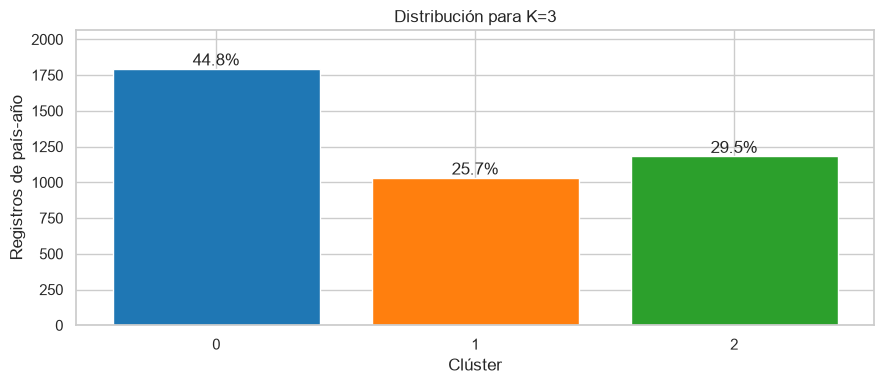

In [7]:
kmeans = modelos[k_elegido]
orden = (base.assign(etiqueta=kmeans.labels_).groupby("etiqueta")
         ["suicide_rate_per_100k"].mean().sort_values().index.to_numpy())
mapa = {int(anterior): nuevo for nuevo, anterior in enumerate(orden)}
resultado = base.copy()
resultado["cluster"] = [mapa[int(c)] for c in kmeans.labels_]
conteo = resultado.groupby("cluster").agg(
    Registros=("year", "size"), Paises_distintos=("country_code", "nunique"))
conteo["Porcentaje (%)"] = 100 * conteo.Registros / len(resultado)
assert conteo.Registros.sum() == len(base)
display(conteo.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(conteo.index.astype(str), conteo.Registros, color=sns.color_palette("tab10", k_elegido))
ax.set(xlabel="Clúster", ylabel="Registros de país-año", title=f"Distribución para K={k_elegido}")
for i, fila in conteo.iterrows():
    ax.text(i, fila.Registros, f"{fila['Porcentaje (%)']:.1f}%", ha="center", va="bottom")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


### 3.1 Centroides y perfiles en unidades originales

Los centroides Z muestran posiciones por encima o por debajo del promedio **en escala
logarítmica estandarizada**. Invertimos `StandardScaler` y luego `expm1` para recuperar
unidades interpretables. Ese centro inverso equivale a una media geométrica de `(1+x)`
menos 1: **no es la media aritmética** de las observaciones originales.

Por eso también mostramos medias, medianas y cuartiles reales. Los países distintos
pueden aparecer en varios grupos a través de los años; sus conteos no se deben sumar
como si fueran poblaciones excluyentes.


Centroides Z:


,log_tasa,log_pib_per_capita,log_poblacion
cluster,,,
0,-0.4930,-0.7510,0.5280
1,-0.2270,0.3310,-1.2110
2,0.9480,0.8500,0.2600


Centroides inversos en unidades originales (no medias aritméticas):


,suicide_rate_per_100k,gdp_per_capita_usd,total_country_population
cluster,,,
0,4.9300,"1,353.8300","19,507,846.1200"
1,6.1300,"7,001.4600","711,047.6900"
2,15.1000,"15,417.6100","11,705,746.2200"


Estadísticas observadas en cada grupo:


suicide_rate_per_100k                        gdp_per_capita_usd  \
                         mean  median    min     max               mean   
cluster                                                                   
0                      5.6900  5.2000 0.5300 21.1600         2,376.4100   
1                      7.8300  6.3800 0.0000 29.7400        13,489.4900   
2                     16.6500 14.7200 4.3100 53.0600        24,769.6300   

                                          total_country_population  \
             median      min          max                     mean   
cluster                                                              
0        1,244.9700 109.5900  31,920.7700          62,176,039.6500   
1        6,320.5600 492.4600 134,965.8200           1,456,350.7000   
2       17,566.1000 653.2900 108,470.3800          34,303,061.4300   

                                             
                 median     min         max  
cluster                                      
0       17,041,397.0000  879159  1414203896  
1          683,651.0000   74912    11121341  
2       10,000,023.0000  549923  1412360000

suicide_rate_per_100k  gdp_per_capita_usd  \
cluster                                                     
0       0.2500                 3.5300            624.2600   
        0.7500                 7.4200          2,909.0300   
1       0.2500                 3.6400          3,233.6400   
        0.7500                10.5600         17,176.2100   
2       0.2500                11.3800          6,669.0700   
        0.7500                20.3200         40,504.8500   

                total_country_population  
cluster                                   
0       0.2500            7,912,558.0000  
        0.7500           37,646,166.0000  
1       0.2500              278,627.7500  
        0.7500            1,989,649.2500  
2       0.2500            4,490,967.0000  
        0.7500           37,974,750.0000

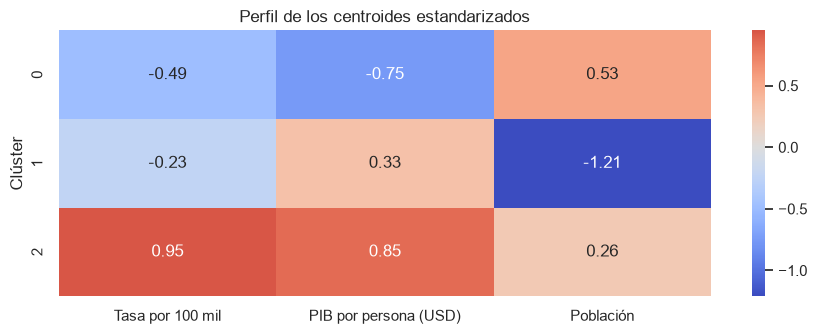

In [8]:
centroides_z = pd.DataFrame(kmeans.cluster_centers_[orden], columns=features)
centroides_z.index.name = "cluster"
centroides_originales = pd.DataFrame(
    np.expm1(scaler.inverse_transform(centroides_z.to_numpy())), columns=variables)
centroides_originales.index.name = "cluster"
perfil = resultado.groupby("cluster")[variables].agg(["mean", "median", "min", "max"])
cuartiles = resultado.groupby("cluster")[variables].quantile([0.25, 0.75])
print("Centroides Z:")
display(centroides_z.round(3))
print("Centroides inversos en unidades originales (no medias aritméticas):")
display(centroides_originales.round(2))
print("Estadísticas observadas en cada grupo:")
display(perfil.round(2))
display(cuartiles.round(2))
fig, ax = plt.subplots(figsize=(9, max(3.5, k_elegido * 0.6)))
sns.heatmap(centroides_z.set_axis(nombres, axis=1), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=ax)
ax.set(title="Perfil de los centroides estandarizados", xlabel="", ylabel="Clúster")
plt.tight_layout()
plt.show()


## 4. Evaluación de silueta y visualización con PCA

### 4.1 Silueta global y por clúster

La silueta compara la distancia media dentro del grupo con la del grupo vecino más
cercano. Valores cercanos a cero indican solapamiento; valores negativos señalan
observaciones más próximas, en promedio, a otro grupo. El promedio global puede ocultar
estas situaciones, por lo que se muestran distribuciones y porcentajes negativos.


Silueta global: 0.3103


,Registros,Media,Mediana,Minima,Negativas_pct
cluster,,,,,
0,1793,0.3548,0.3834,-0.0082,0.1673
1,1030,0.2036,0.2093,-0.0874,10.3883
2,1181,0.3357,0.3621,0.0001,0.0000


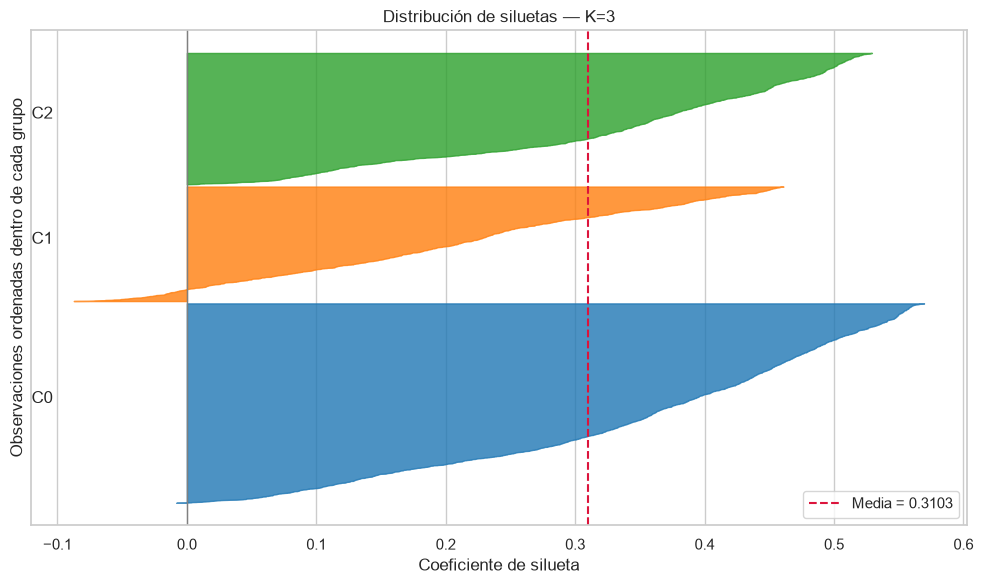

In [9]:
with threadpool_limits(limits=1):
    resultado["silueta"] = silhouette_samples(X_scaled, resultado.cluster)
sil_global = resultado.silueta.mean()
assert np.isclose(sil_global, tabla_k.set_index("K").loc[k_elegido, "Silueta"])
resumen_silueta = resultado.groupby("cluster").agg(
    Registros=("silueta", "size"), Media=("silueta", "mean"),
    Mediana=("silueta", "median"), Minima=("silueta", "min"),
    Negativas_pct=("silueta", lambda s: 100 * s.lt(0).mean()))
print(f"Silueta global: {sil_global:.4f}")
display(resumen_silueta.round(4))
fig, ax = plt.subplots(figsize=(10, 6))
inicio = 10
colores = sns.color_palette("tab10", k_elegido)
for cluster in range(k_elegido):
    valores = np.sort(resultado.loc[resultado.cluster.eq(cluster), "silueta"])
    fin = inicio + len(valores)
    ax.fill_betweenx(np.arange(inicio, fin), 0, valores, color=colores[cluster], alpha=0.8)
    ax.text(-0.12, (inicio + fin) / 2, f"C{cluster}")
    inicio = fin + 20
ax.axvline(sil_global, color="crimson", linestyle="--", label=f"Media = {sil_global:.4f}")
ax.axvline(0, color="gray", linewidth=1)
ax.set(xlabel="Coeficiente de silueta", ylabel="Observaciones ordenadas dentro de cada grupo",
       title=f"Distribución de siluetas — K={k_elegido}", yticks=[])
ax.legend()
plt.tight_layout()
plt.show()


### 4.2 Visualización PCA del modelo con K=3

PCA resume las tres variables estandarizadas en dos componentes para visualizar
únicamente los tres clústeres del modelo con **K=3**. K-Means y la silueta se calculan
en el espacio completo; PCA se utiliza solo para representar los resultados.

Las etiquetas C0, C1 y C2 se ordenan por tasa media ascendente, como en el análisis
de perfiles. Los colores identifican los grupos y las X negras marcan sus centroides
proyectados. La varianza explicada indica cuánta información conserva el plano.

Varianza explicada: PC1=40.84%, PC2=33.43%, acumulada=74.27%


,PC1,PC2
log_tasa,0.5900,0.5530
log_pib_per_capita,0.7090,-0.0060
log_poblacion,-0.3860,0.8330


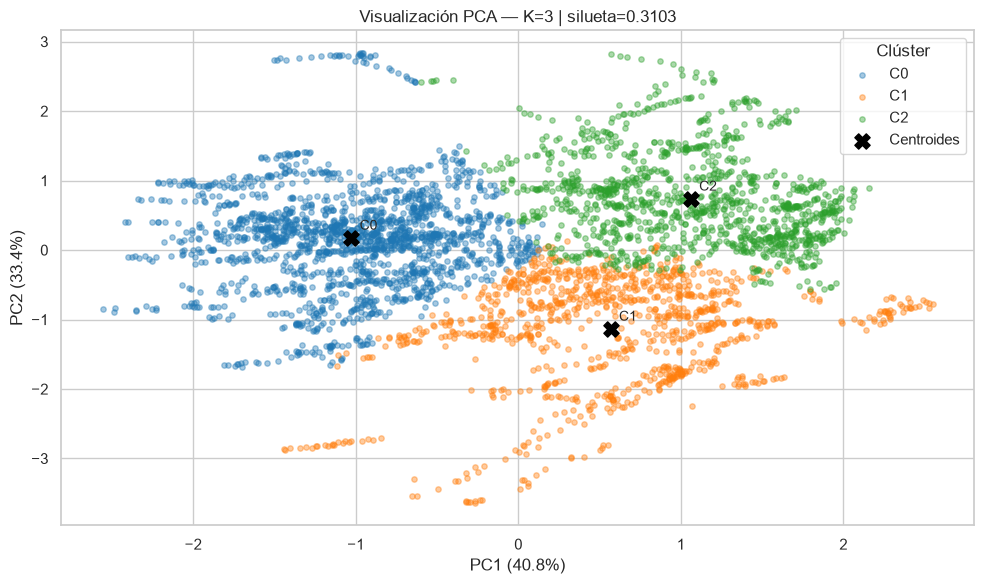

La proyección conserva **74.27%** de la varianza. El 25.73% restante queda fuera del plano; por ello, la superposición visual no reemplaza la silueta en tres dimensiones.

In [10]:
pca = PCA(n_components=2, svd_solver="full")
X_pca = pca.fit_transform(X_scaled)
varianza = 100 * pca.explained_variance_ratio_
print(f"Varianza explicada: PC1={varianza[0]:.2f}%, PC2={varianza[1]:.2f}%, "
      f"acumulada={varianza.sum():.2f}%")
display(pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(3))

# Se representa únicamente el modelo con K=3.
k_pca = 3
modelo = modelos[k_pca]
orden_pca = (base.assign(etiqueta=modelo.labels_).groupby("etiqueta")
             .suicide_rate_per_100k.mean().sort_values().index.to_numpy())
paleta = sns.color_palette("tab10", k_pca)
fig, ax = plt.subplots(figsize=(10, 6))
for nuevo, anterior in enumerate(orden_pca):
    mascara = modelo.labels_ == anterior
    ax.scatter(X_pca[mascara, 0], X_pca[mascara, 1], s=15, alpha=0.4,
               color=paleta[nuevo], label=f"C{nuevo}")
centros = pca.transform(modelo.cluster_centers_[orden_pca])
ax.scatter(centros[:, 0], centros[:, 1], c="black", marker="X", s=120,
           label="Centroides", zorder=5)
for nuevo, (x, y) in enumerate(centros):
    ax.annotate(f"C{nuevo}", (x, y), xytext=(6, 6), textcoords="offset points", fontsize=10)
sil = tabla_k.set_index("K").loc[k_pca, "Silueta"]
ax.set(title=f"Visualización PCA — K={k_pca} | silueta={sil:.4f}",
       xlabel=f"PC1 ({varianza[0]:.1f}%)", ylabel=f"PC2 ({varianza[1]:.1f}%)")
ax.legend(title="Clúster")
plt.tight_layout()
plt.show()
display(Markdown(f"La proyección conserva **{varianza.sum():.2f}%** de la varianza. "
                 f"El {100 - varianza.sum():.2f}% restante queda fuera del plano; "
                 "por ello, la superposición visual no reemplaza la silueta en tres dimensiones."))

## 5. Interpretación de los grupos y contexto

### 5.1 Perfiles descriptivos

Las comparaciones «menor» y «mayor» se refieren a esta muestra y a estos centroides,
no a umbrales clínicos o categorías oficiales. La tasa ya participa en el entrenamiento;
observar diferencias de tasa entre grupos describe el resultado, pero no lo valida de
forma independiente. Los ejemplos más cercanos al centro ayudan a reconocer cada perfil.


- **C0**: 1793 registros (44.8%). Medianas: tasa **5.20** por 100.000, PIB por persona **USD 1,245** y población **17,041,397**. Tasa por 100 mil: por debajo de la media logarítmica; PIB por persona (USD): por debajo de la media logarítmica; Población: por encima de la media logarítmica.
- **C1**: 1030 registros (25.7%). Medianas: tasa **6.38** por 100.000, PIB por persona **USD 6,321** y población **683,651**. Tasa por 100 mil: por debajo de la media logarítmica; PIB por persona (USD): por encima de la media logarítmica; Población: por debajo de la media logarítmica.
- **C2**: 1181 registros (29.5%). Medianas: tasa **14.72** por 100.000, PIB por persona **USD 17,566** y población **10,000,023**. Tasa por 100 mil: por encima de la media logarítmica; PIB por persona (USD): por encima de la media logarítmica; Población: por encima de la media logarítmica.

,cluster,country,year,suicide_rate_per_100k,gdp_per_capita_usd,total_country_population,distancia_centro
708,0,Côte d'Ivoire,2004,5.1500,"1,199.8250",19595000,0.0960
709,0,Côte d'Ivoire,2005,5.1800,"1,197.7460",20068458,0.1020
710,0,Côte d'Ivoire,2006,5.2900,"1,230.4310",20546802,0.1100
1413,1,Equatorial Guinea,2005,7.1200,"8,673.9030",947367,0.2790
1414,1,Equatorial Guinea,2006,6.6900,"10,184.8840",990343,0.3210
1412,1,Equatorial Guinea,2004,7.3100,"4,901.3010",899917,0.3460
930,2,Czechia,2006,14.5600,"15,259.0790",10238905,0.0860
929,2,Czechia,2005,15.8800,"13,442.4920",10211216,0.1340
931,2,Czechia,2007,14.2600,"18,452.6530",10298828,0.1560


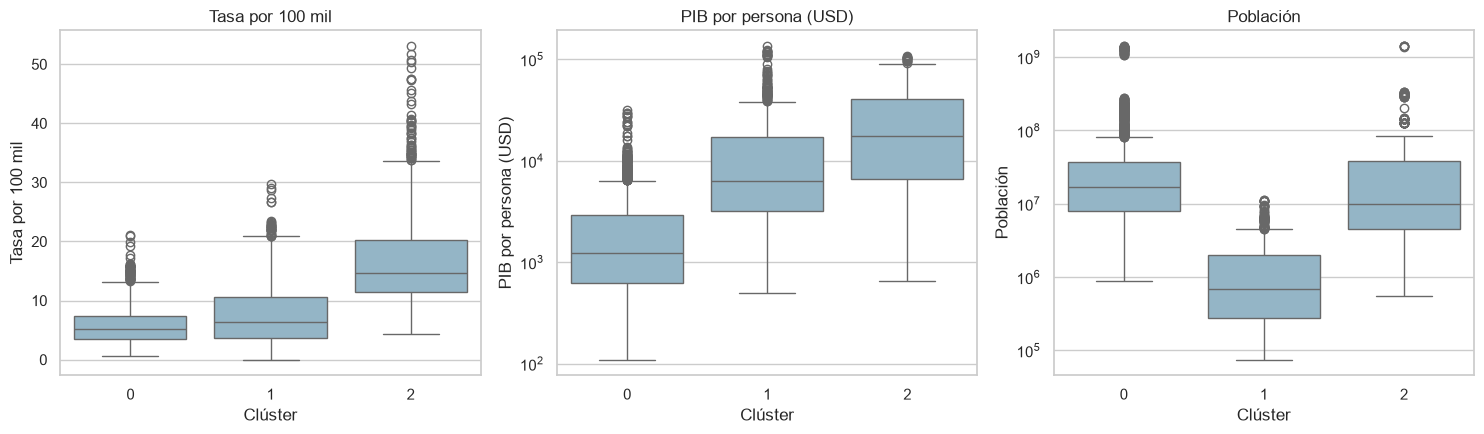

In [11]:
medianas = resultado.groupby("cluster")[variables].median()
lineas = []
for cluster in range(k_elegido):
    m = medianas.loc[cluster]
    z = centroides_z.loc[cluster]
    rasgos = [f"{nombre}: {'por encima' if valor > 0 else 'por debajo'} de la media logarítmica"
              for nombre, valor in zip(nombres, z)]
    lineas.append(f"- **C{cluster}**: {int(conteo.loc[cluster, 'Registros'])} registros "
                  f"({conteo.loc[cluster, 'Porcentaje (%)']:.1f}%). "
                  f"Medianas: tasa **{m.iloc[0]:.2f}** por 100.000, PIB por persona "
                  f"**USD {m.iloc[1]:,.0f}** y población **{m.iloc[2]:,.0f}**. "
                  + "; ".join(rasgos) + ".")
display(Markdown("\n".join(lineas)))

# Distancia calculada en las mismas tres dimensiones usadas por K-Means.
centro_por_fila = centroides_z.to_numpy()[resultado.cluster.to_numpy()]
resultado["distancia_centro"] = np.linalg.norm(X_scaled - centro_por_fila, axis=1)
ejemplos = (resultado.sort_values("distancia_centro")
            .groupby("cluster", sort=True).head(3)
            .sort_values(["cluster", "distancia_centro"]))
display(ejemplos[["cluster", "country", "year", *variables, "distancia_centro"]].round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, variable, nombre in zip(axes, variables, nombres):
    sns.boxplot(data=resultado, x="cluster", y=variable, color="#8cb8ce", ax=ax)
    if variable != "suicide_rate_per_100k":
        ax.set_yscale("log")
    ax.set(xlabel="Clúster", ylabel=nombre, title=nombre)
plt.tight_layout()
plt.show()


#### C0 · Menor PIB por persona y mayor población típica

Este grupo reúne **1.793 observaciones de país-año (44,78%)** y es el más numeroso. Su rasgo más marcado en el centroide es el **PIB per cápita por debajo del promedio logarítmico estandarizado (Z = −0,75)**. Se combina con una población por encima de ese promedio (Z = +0,53) y una tasa por debajo (Z = −0,49).

En unidades originales, las medianas son **USD 1.244,97 de PIB por persona**, **17,04 millones de habitantes** y **5,20 suicidios por cada 100.000 habitantes**. Frente a los otros dos grupos, presenta el menor PIB per cápita mediano, la mayor población mediana y la menor tasa mediana. El 50% central de sus tasas se encuentra entre **3,53 y 7,42**.

**Interpretación:** el perfil combina una menor producción económica por persona con poblaciones relativamente grandes y tasas observadas más bajas dentro de esta muestra. La población y el PIB por persona ayudan a distinguirlo de C1, cuyas tasas se superponen parcialmente. Esto no implica que un menor PIB proteja frente al suicidio: el modelo identifica una combinación de características, sin establecer causas.

Como ejemplo cercano al centroide aparece **Côte d'Ivoire en 2004–2006**. Estos registros ilustran el perfil en esos años; no representan a todas las observaciones del grupo ni una clasificación permanente del país.

#### C1 · Menor población y tasa mediana intermedia

Este grupo contiene **1.030 observaciones de país-año (25,72%)**. Su característica más distintiva es la **población reducida (Z = −1,21)**: es la desviación de mayor magnitud de su centroide respecto del promedio logarítmico estandarizado. El PIB per cápita está por encima de ese promedio (Z = +0,33), mientras que la tasa queda ligeramente por debajo (Z = −0,23).

Las medianas son **683.651 habitantes**, **USD 6.320,56 de PIB por persona** y **6,38 suicidios por cada 100.000 habitantes**. La población mediana es mucho menor que la de C0 y C2. La tasa y el PIB por persona ocupan una posición intermedia entre los tres perfiles; el 50% central de las tasas está entre **3,64 y 10,56**, con amplio solapamiento respecto de C0.

**Interpretación:** la escala demográfica caracteriza especialmente a este grupo. No basta con describirlo como un nivel intermedio de tasa, porque su separación también incorpora poblaciones pequeñas y un PIB por persona mayor que el de C0. El grupo mantiene heterogeneidad económica: el 50% central del PIB per cápita abarca aproximadamente **USD 3.234 a USD 17.176**.

**Equatorial Guinea en 2004–2006** aporta los ejemplos más próximos al centroide mostrados en la tabla. Son referencias de combinaciones concretas de país y año, no evidencia de que todos los países poco poblados compartan la misma tasa.

#### C2 · Mayor tasa y mayor PIB por persona

Este grupo agrupa **1.181 observaciones de país-año (29,50%)**. Sus rasgos centrales más destacados son la **tasa por encima del promedio logarítmico estandarizado (Z = +0,95)** y el **PIB per cápita también por encima (Z = +0,85)**. La población tiene una desviación positiva menor (Z = +0,26), por lo que caracteriza menos al centroide que las otras dos variables.

Las medianas son **14,72 suicidios por cada 100.000 habitantes**, **USD 17.566,10 de PIB por persona** y **10,00 millones de habitantes**. Presenta la mayor tasa mediana y el mayor PIB per cápita mediano de los tres grupos. El 50% central de sus tasas se sitúa entre **11,38 y 20,32**, por encima de los intervalos centrales de C0 y C1, aunque existen observaciones superpuestas en los extremos.

**Interpretación:** el perfil combina tasas observadas relativamente elevadas con mayor producción económica por persona. La coincidencia de ambos rasgos no demuestra que el PIB provoque esas tasas, ni que cada registro del grupo tenga una tasa superior a todos los registros de los otros grupos. Además, como la tasa forma parte del entrenamiento, su diferencia entre clústeres es descriptiva y no constituye una validación independiente.

Los registros de **Czechia en 2005–2007** son ejemplos cercanos al centroide. Ayudan a describir esta combinación de características en ese periodo, sin extrapolarla al riesgo de personas individuales.

### Lectura conjunta de los perfiles

La solución obtenida separa **tres combinaciones de tasa y contexto**, no únicamente tres niveles de tasa. C0 reúne observaciones con menor PIB por persona y una población relativamente grande; C1 destaca por poblaciones menores y una tasa mediana cercana a la de C0; C2 presenta una tasa mediana más alta junto con mayor PIB por persona. Las medianas de tasa son **5,20**, **6,38** y **14,72** por cada 100.000 habitantes, respectivamente.

La diferencia entre C0 y C1 se aprecia especialmente en población y PIB per cápita. Esto muestra por qué una clasificación basada solo en la tasa perdería parte del contexto que aquí se decidió incluir. Los boxplots también muestran valores superpuestos: el centro de un grupo no describe a todas sus observaciones y no permite atribuir causalidad a las diferencias económicas.

La silueta global de **0,3103** y el **2,75% de siluetas negativas** aconsejan interpretar los perfiles como resúmenes con fronteras imperfectas. PCA conserva **74,27%** de la varianza; el solapamiento en el gráfico debe leerse junto con las métricas del espacio completo.

*Interpretación de la ejecución guardada; revisar estas cifras si se cambia el dataset o la configuración.*

### 5.2 Distribución temporal y contexto externo

El año y el PIB total no entraron al modelo. Revisamos su distribución para describir
la composición de los grupos. El PIB total está relacionado algebraicamente con las
variables incluidas, por lo que esta tabla tampoco constituye validación independiente.
Las cifras de PIB del archivo se usan tal como están; no se aplica ajuste por inflación
ni paridad de poder adquisitivo. Esto limita la interpretación de cambios temporales.


,Anio_min,Anio_max,PIB_total_mediano,Paises_distintos
cluster,,,,
0,2000,2021,"20,559,250,000.0000",94
1,2000,2021,"5,431,076,280.4300",58
2,2000,2021,"199,765,859,570.9400",72


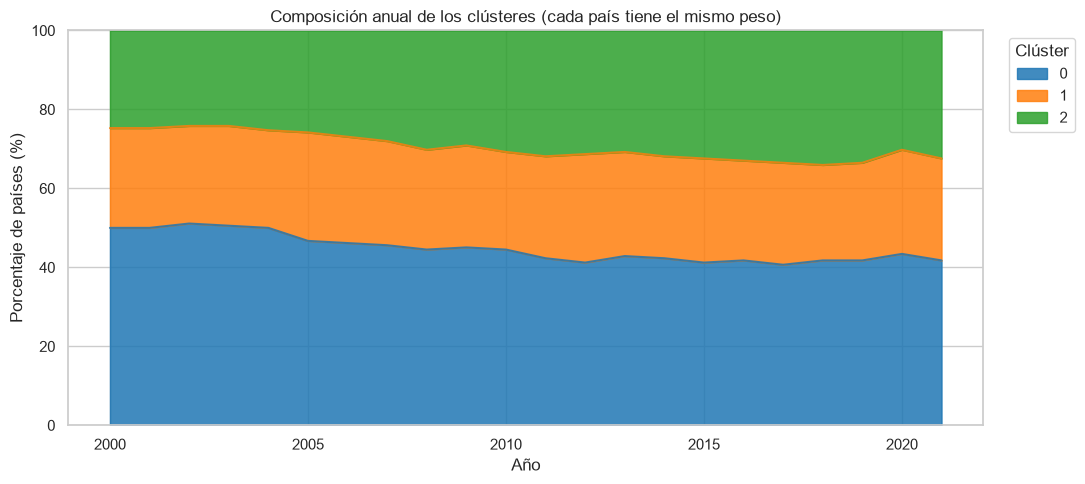

**35 de 182 países** aparecen en más de un clúster durante el periodo. Esto confirma que las etiquetas corresponden a observaciones de país-año y deben interpretarse junto con el año, no como atributos permanentes.

In [12]:
contexto = resultado.groupby("cluster").agg(
    Anio_min=("year", "min"), Anio_max=("year", "max"),
    PIB_total_mediano=("gdp_usd", "median"),
    Paises_distintos=("country_code", "nunique"))
display(contexto.round(2))
por_anio = pd.crosstab(resultado.year, resultado.cluster, normalize="index") * 100
ax = por_anio.plot.area(figsize=(11, 5), color=colores, alpha=0.85)
ax.set(xlabel="Año", ylabel="Porcentaje de países (%)", ylim=(0, 100),
       title="Composición anual de los clústeres (cada país tiene el mismo peso)")
ax.legend(title="Clúster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
grupos_por_pais = resultado.groupby("country_code").cluster.nunique()
display(Markdown(f"**{grupos_por_pais.gt(1).sum()} de {len(grupos_por_pais)} países** "
                 "aparecen en más de un clúster durante el periodo. Esto confirma que "
                 "las etiquetas corresponden a observaciones de país-año y deben "
                 "interpretarse junto con el año, no como atributos permanentes."))


### 5.3 Sensibilidad: mantener la tasa sin logaritmo

Probamos una decisión alternativa: conservar la tasa en su escala original antes del
Z-score y mantener `log1p` para PIB per cápita y población. Se fija el mismo K, semilla
y `n_init` para aislar el efecto de esa transformación. ARI compara las asignaciones
de los mismos registros. **Las inercias no se comparan entre ambas representaciones**;
sus distancias tienen otra geometría. Las siluetas se reportan en el espacio de cada
modelo y no bastan por sí solas para declarar superior un preprocesamiento.


In [13]:
X_alternativo = X_log.copy()
X_alternativo["log_tasa"] = base.suicide_rate_per_100k
X_alternativo = X_alternativo.rename(columns={"log_tasa": "tasa_sin_log"})
X_alt_scaled = StandardScaler().fit_transform(X_alternativo)
with threadpool_limits(limits=1):
    modelo_alt = KMeans(n_clusters=k_elegido, random_state=SEMILLA,
                        n_init=N_INIT, max_iter=500, algorithm="lloyd").fit(X_alt_scaled)
    sil_alt = silhouette_score(X_alt_scaled, modelo_alt.labels_)
ari_alt = adjusted_rand_score(kmeans.labels_, modelo_alt.labels_)
display(pd.DataFrame({"Preparación": ["log1p en las tres variables", "Tasa sin log1p"],
                      "K": [k_elegido, k_elegido], "Silueta en su espacio": [sil_global, sil_alt]}))
display(pd.crosstab(resultado.cluster, modelo_alt.labels_,
                    rownames=["Modelo principal"], colnames=["Modelo alternativo"]))
display(Markdown(f"El ARI entre preparaciones es **{ari_alt:.4f}**. "
                 "La tabla de cruce permite ver qué grupos se conservan o se redistribuyen. "
                 "La solución principal mantiene el logaritmo de la tasa porque prioriza "
                 "diferencias relativas y reduce el peso de los extremos; el contraste "
                 "documenta cuánto depende la partición de esa decisión."))


,Preparación,K,Silueta en su espacio
0,log1p en las tres variables,3,0.3103
1,Tasa sin log1p,3,0.3299


Modelo alternativo,0,1,2
Modelo principal,,,
0,1762,2,29
1,4,21,1005
2,57,1022,102


El ARI entre preparaciones es **0.8599**. La tabla de cruce permite ver qué grupos se conservan o se redistribuyen. La solución principal mantiene el logaritmo de la tasa porque prioriza diferencias relativas y reduce el peso de los extremos; el contraste documenta cuánto depende la partición de esa decisión.

### Balance de estabilidad y sensibilidad

El **ARI mínimo de 0,9881** entre semillas indica que las inicializaciones ensayadas producen asignaciones muy similares para K=3. Al conservar la tasa sin logaritmo, el ARI baja a **0,8599**: sigue existiendo un acuerdo alto, pero algunas observaciones se redistribuyen. La elección de la representación influye más que el punto de partida del optimizador en estas pruebas.

Asimismo, **35 de los 182 países** aparecen en más de un grupo a lo largo del periodo. Las transiciones describen cambios en el conjunto de las tres variables; no deben atribuirse exclusivamente a cambios de la tasa. El siguiente paso, si se ampliara el proyecto, sería contrastar la estabilidad por periodos y países completos, además de las inicializaciones.

## 6. Conclusiones

El siguiente resumen se genera a partir de los resultados ejecutados, para mantener
las cifras y la selección de K alineadas si se actualiza el dataset.


In [14]:
negativas = 100 * resultado.silueta.lt(0).mean()
display(Markdown(
    f"1. **Selección:** de los 14 valores de K evaluados, se selecciona **K={k_elegido}** "
    f"por la mayor silueta (**{sil_global:.4f}**), sobre {len(base):,} registros "
    f"de {base.country_code.nunique()} países. Las tablas comparan los tres rangos, "
    "sin usar la disminución de WCSS como único argumento.\n"
    f"2. **Tamaños y solapamiento:** los grupos contienen entre "
    f"{conteo.Registros.min():,} y {conteo.Registros.max():,} observaciones; "
    f"**{negativas:.2f}%** de las siluetas individuales son negativas. Los perfiles "
    "resumen tendencias y no constituyen fronteras naturales exactas.\n"
    f"3. **Estabilidad:** el ARI mínimo entre semillas para K={k_elegido} es "
    f"**{estabilidad.loc[k_elegido, 'ARI mínimo']:.4f}**. Frente a la preparación "
    f"sin logaritmo de la tasa, el ARI es **{ari_alt:.4f}**: la reproducibilidad "
    "numérica y la sensibilidad metodológica deben evaluarse por separado.\n"
    f"4. **Visualización:** PCA conserva **{varianza.sum():.2f}%** de la varianza "
    "en dos componentes. La evaluación corresponde a las tres dimensiones originales "
    "del modelo, no solamente a los puntos visibles en el plano."
))


1. **Selección:** de los 14 valores de K evaluados, se selecciona **K=3** por la mayor silueta (**0.3103**), sobre 4,004 registros de 182 países. Las tablas comparan los tres rangos, sin usar la disminución de WCSS como único argumento.
2. **Tamaños y solapamiento:** los grupos contienen entre 1,030 y 1,793 observaciones; **2.75%** de las siluetas individuales son negativas. Los perfiles resumen tendencias y no constituyen fronteras naturales exactas.
3. **Estabilidad:** el ARI mínimo entre semillas para K=3 es **0.9881**. Frente a la preparación sin logaritmo de la tasa, el ARI es **0.8599**: la reproducibilidad numérica y la sensibilidad metodológica deben evaluarse por separado.
4. **Visualización:** PCA conserva **74.27%** de la varianza en dos componentes. La evaluación corresponde a las tres dimensiones originales del modelo, no solamente a los puntos visibles en el plano.

### Alcance y limitaciones

- El agrupamiento es descriptivo y no supervisado: no tiene una etiqueta real contra
  la cual calcular exactitud, ni estima riesgo individual o efectos causales del PIB.
- La tasa utilizada es la disponible para todas las edades; el análisis no controla
  diferencias en estructura etaria, calidad de registro o subregistro entre países.
- Los años de un mismo país comparten características. Una evaluación futura de
  generalización debería separar países o periodos completos, evitando mezclar años
  del mismo país entre entrenamiento y evaluación.
- Se heredan las exclusiones e imputaciones del ETL. La cobertura no representa todos
  los países del mundo y los valores económicos completados pueden influir en distancias.
- K-Means favorece grupos compactos en distancia euclidiana. Los rangos ensayados,
  transformaciones y pesos iguales tras el escalado condicionan la solución; las
  métricas internas no prueban que sea la única segmentación válida.

